---
---

<h1><center><ins>Exercise Sheet 7</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [2]:
import numpy as np
import matplotlib.pyplot as plt

""" 
Set some defaults, most of all: LARGE fonts
"""
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'xx-large',
          'figure.figsize': (12, 7),
         'axes.labelsize': 'xx-large',
         'axes.titlesize':'xx-large',
         'xtick.labelsize':'xx-large',
         'ytick.labelsize':'xx-large'}
pylab.rcParams.update(params)

Backward Euler for exponential like function $\frac{dy}{dt} = a y$:

 $y_{n+1} = y_n + \Delta t \, (\frac{dy}{dt})$, hence $y_{n+1} = y_n + a \, \Delta t \, y_{n+1}$, hence $y_{n+1} = \frac{y_n}{1 - a \, \Delta t}$.

In [20]:
def forw_euler(df, t0, tend, y0, dt):
    """
    df:     callable function, the derivative, can be a vector
    t0:     start time
    tend:   end time
    y0:     initial condition, can be a vector, must have same dimens as df
    dt:     time increment
    Forward Euler integration of a single or coupled system of ODE's
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """
    ts = [t0]
    ys = [np.array(y0, dtype=float)]
    t = t0
    y = np.array(y0, dtype=float)

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        y = y + h * df(t, y)        # new y equals old y + dt * slope at old t
        t += h
        ys.append(y.copy())         # avoid side effects, remember that y can be a vector
        ts.append(t)
    return np.array(ts), np.array(ys)

def backw_euler_decay(a, t0, tend, y0, dt):
    """
    a:      exponent in exponential
    t0:     start time
    tend:   end time
    y0:     initial condition
    dt:     time increment
    Backward Euler integration for special case of exponential
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """
    ts = [t0]
    ys = [y0]
    t = t0
    y = y0

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        y = y / ( 1 - a*h)
        t += h
        ys.append(y)       
        ts.append(t)
    return np.array(ts), np.array(ys)

## Exercise 1 - Backward Euler:

Consider the following first-order ODE:

$$ \frac{d y}{dt} = - 3 y \ , $$

**(A)** Solve this ODE with **your own forward Euler** implementation for $0\leq t\leq20$. Use the following step sizes: $\Delta t = 0.1, 0.25, 0.5, 0.75$, and plot the numerical solution for all four step sizes in four different figures. Also compare it with the exact analytical solution in the corresponding plot. Discuss your findings.

**(B)** Now implement **your own backward Euler** implementation and repeat all the steps from **(A)**. What do you notice?

**(C)** What complication arises in the implementation of the backward Euler, if we replace the right hand side of the ODE with $ (1-\frac{y}{3})y $? What kind of numerical methods already known from the lecture can you use to solve the arising equation? Please implement them to solve this ODE with the backward Euler and compare your solution with analytic one by plotting them in a figure.

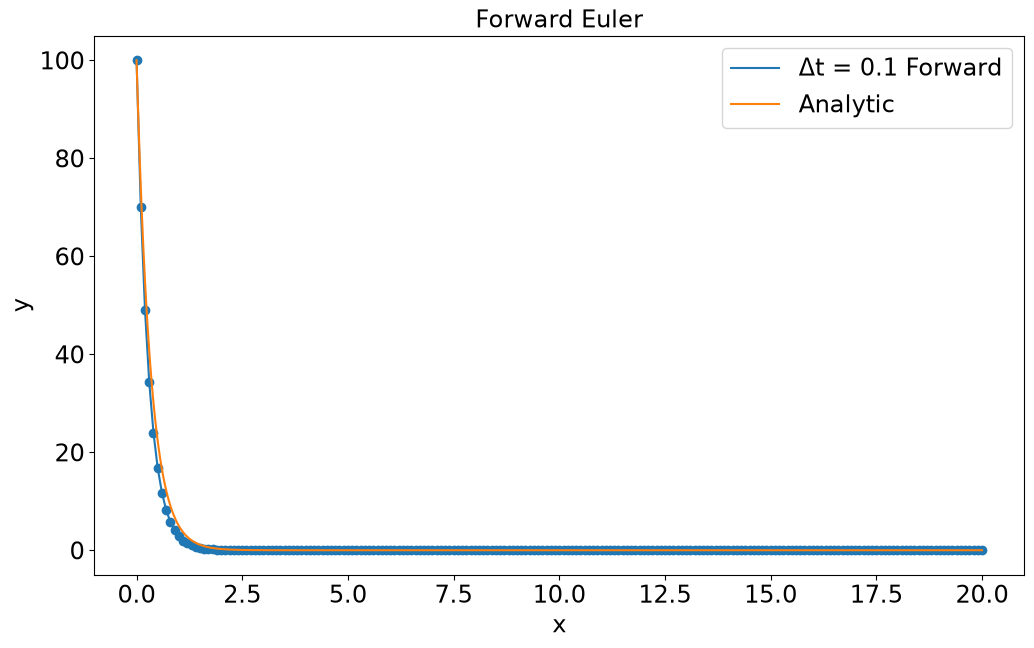

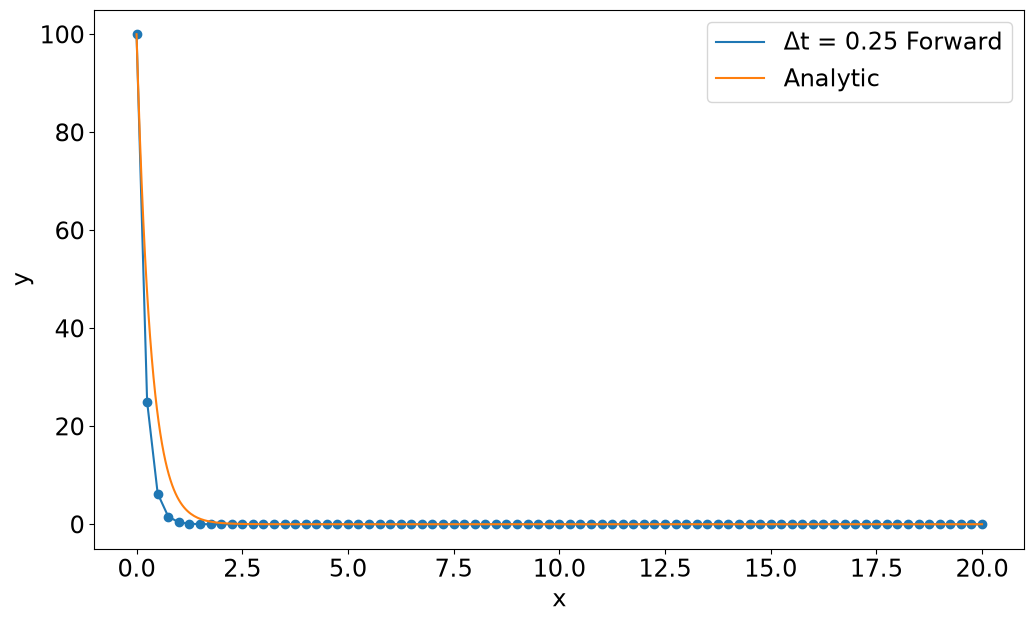

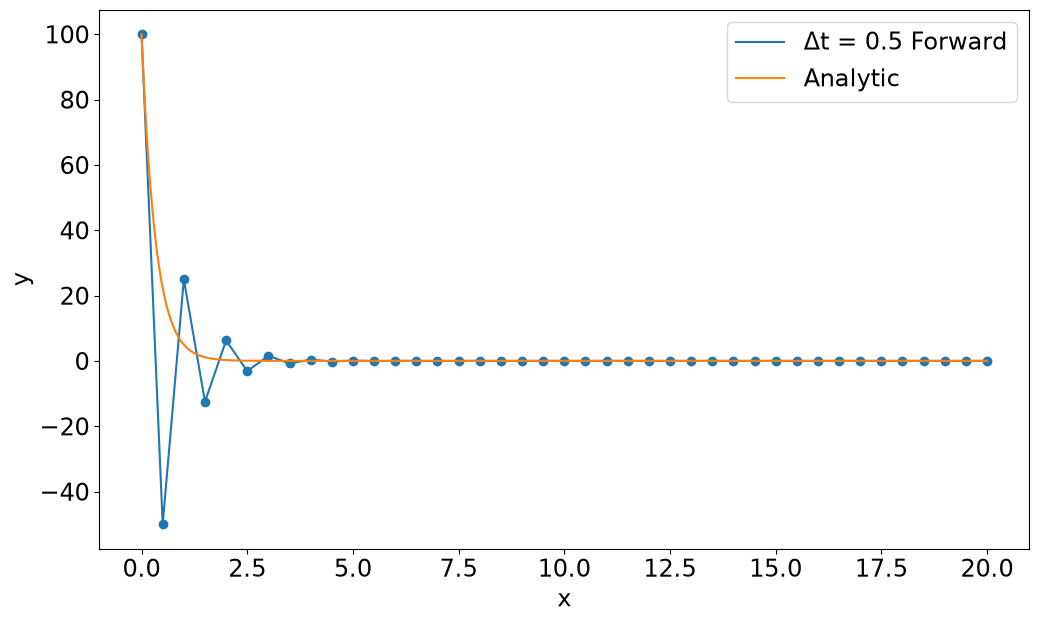

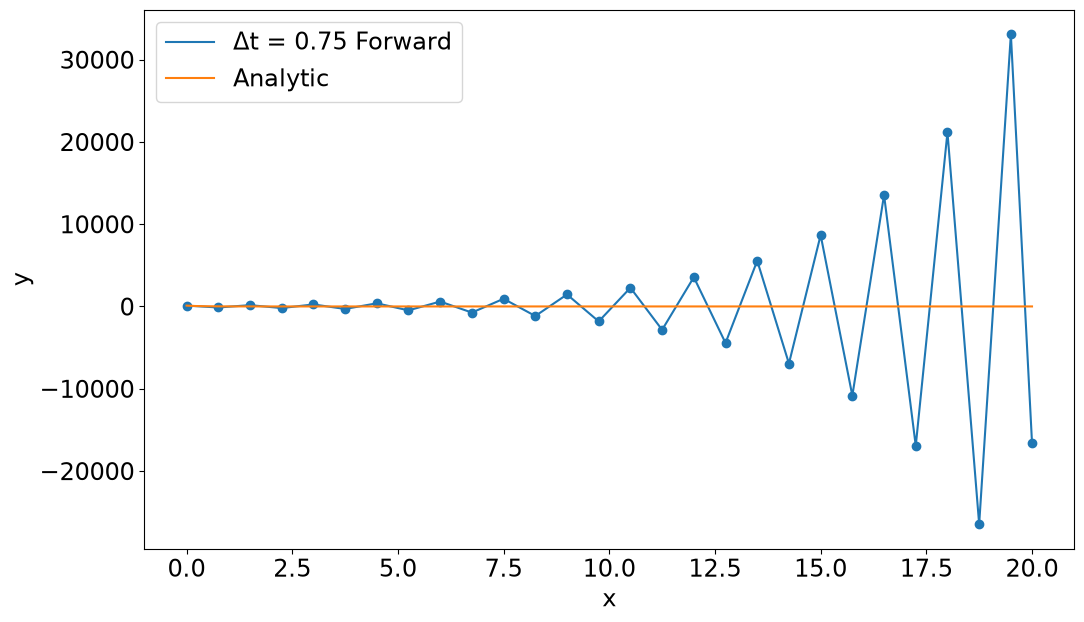

In [22]:
def decay(t, y):
    return -3 * y

def decay_analytic(t, lam, y0):
    return y0 * np.exp(-lam * t)

N0 = 100
start_time = 0
end_time = 20
dts = [0.1, 0.25, 0.5, 0.75]
ts = np.linspace(start_time, end_time, 500)
Ns = decay_analytic(ts, 3, N0)
for dt in dts:
    t, y = forw_euler(decay, start_time, end_time, N0, dt)
    plt.figure()
    plt.plot(t, y, label=r'$\Delta$' + f't = {dt} Forward')
    plt.plot(ts, Ns, label='Analytic')
    plt.scatter(t, y)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    if dt == 0.1:
        plt.title('Forward Euler')
    plt.show()

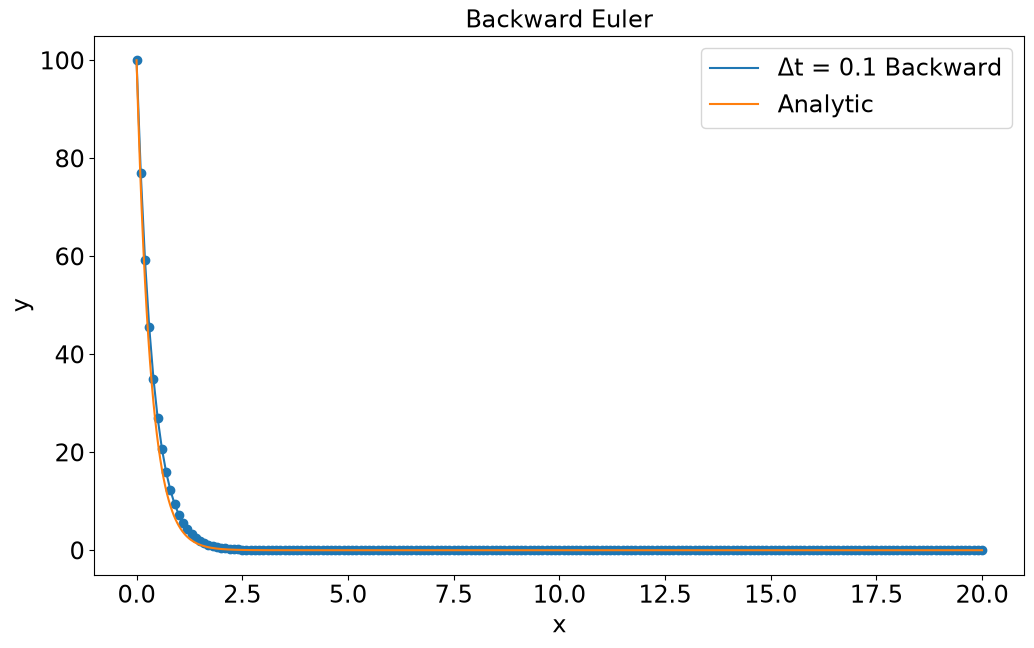

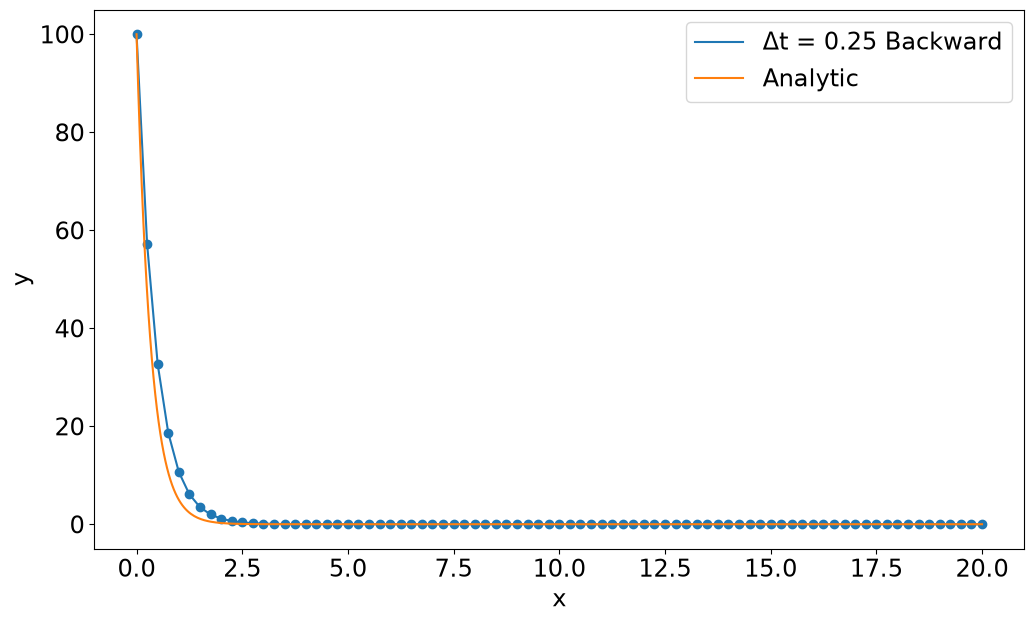

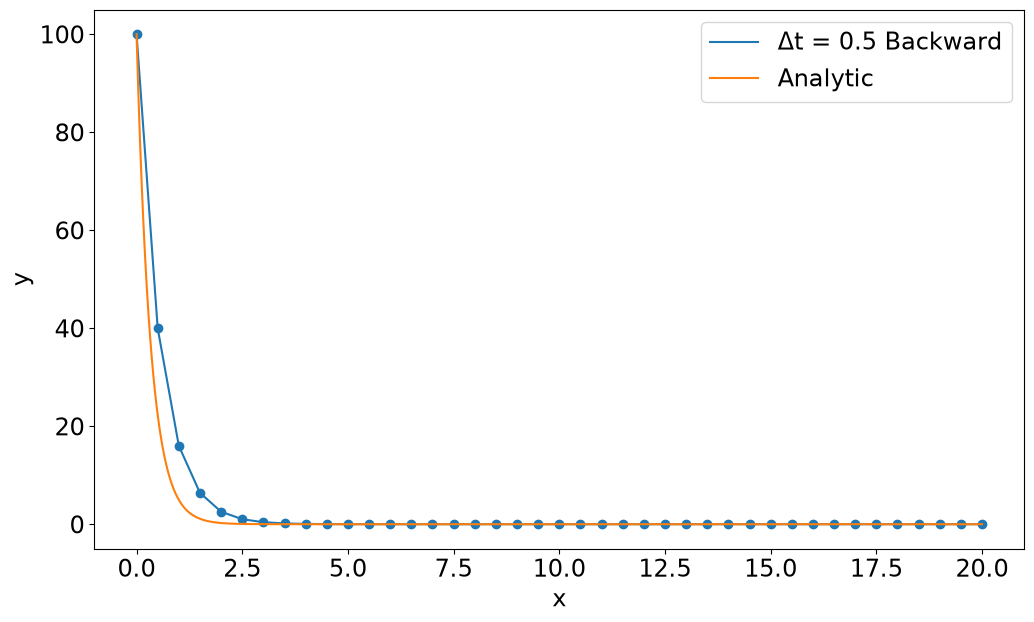

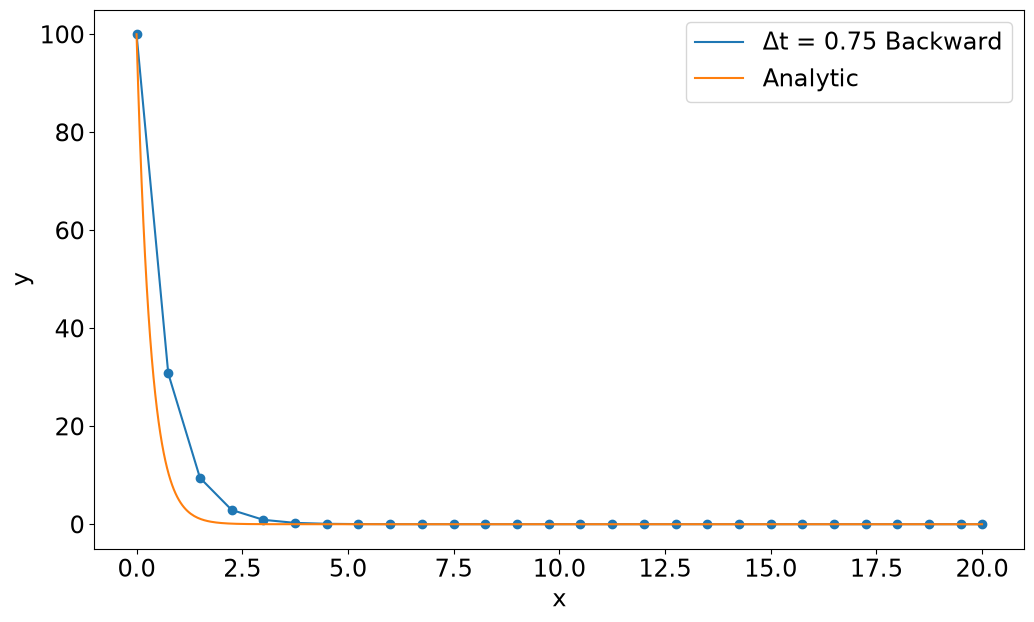

In [24]:
dts = [0.1, 0.25, 0.5, 0.75]
ts = np.linspace(start_time, end_time, 500)
Ns = decay_analytic(ts, 3, N0)
for dt in dts:
    t_b, y_b = backw_euler_decay(-3, start_time, end_time, N0, dt)
    plt.figure()
    plt.plot(t_b, y_b,label=r'$\Delta$' + f't = {dt} Backward')
    plt.plot(ts, Ns, label='Analytic')
    plt.scatter(t_b, y_b)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    if dt == 0.1:
        plt.title('Backward Euler')
    plt.show()

For Forward Euler $\Delta t = 0.1$ the solution is ok, for 0.25 still useful, but for values ~0.5 and higher the solution diverges and becomes totally useless.

On the other hand, Backward Euler gives useful results even with $\Delta t = 0.75$

## Exercise 2 - Backward Euler Part 2:

Consider now the following second-order ODE:

$$ y^{\prime\prime} + 6 y^{\prime} + 5y = 10, $$

with initial conditions of $y(0) = 0$ and $y^{\prime}(0) = 5.$

**(A)** Solve this ODE with **your own backward Euler** implementation for $0\leq t\leq5$. What is the linear system of equation that you have to solve? (write it down in matrix notation). Within **your own backward Euler** implementation you are free to solve this system of equation using either numerical methods (e.g. np.linalg.solve) or invert the matrix by hand. Use a step size of 0.1 and 0.5. Plot the absolute error of the numerical solutions for both steps sizes compared to the exact solution. The exact solution is 

$$ y(t) = -\frac{3}{4}e^{-5t} -\frac{5}{4}e^{-t} + 2. $$


**(B)** Repeat **(A)** using **forward Euler**. What do you notice?

## Exercise 3 - More Oscillators:

Consider again a system of a mass that is attached to a spring. We have seen (look at Exercise Sheet 6 Exercise Number 3) that the resuling ODE describing such a system is of the form

$$ \frac{d^2 x}{dt^2} = - \frac{k}{m} x \ , $$

where $m$ is the mass of your particle, $k$ is the spring constant, and $x$ is the displacement from the equilibrium position.

**(A)** Implement the Leapfrog integration in oder to solve this ODE. Follow the section "Algorithm" under https://en.wikipedia.org/wiki/Leapfrog_integration. Consider the same values for the constants and initial conditions from Exercise Sheet 6 and plot your result by comparing with the analytic solution. Is the accuracy the same as for the Kunge-Kutta method? Why is this integrator called leapfrog? Name one advantage of the leapfrog integration over other methods such as Kunge-Kutta.

Consider now the damped oscillator of the form:

$$ \frac{d^2 x}{dt^2} = - \frac{k}{m} x - \frac{D}{m} \frac{dx}{dt} \ , $$

where $D$ is an additional friction coefficient.

**(B)**
Solve this ODE with the Runge-Kutta method. Either use the build-in python function or your own implementation. Play around with different values for $D$ and compare it to the analytic solution (you may use : https://lemesurierb.people.charleston.edu/numerical-methods-and-analysis-python/main/ODE-IVP-4-system-higher-order-equations-python.html#equation-equation-damped-mass-spring to help you with the analytic solution). Consider all three possibilities of the system being (1) underdamped, (2) overdamped and (3) critically damped (What do these terms mean?). Make a plot for all three cases to show your numerical and analytic solution.

**(C)**
What problem arises if you were to solve the damped oscillator with the leapfrog algorithm? What could be a possible solution to that problem?